## Conceptual definition

The transition model assigns probabilities to candidate pass destinations, conditional on attempting a pass. This differs from the probability that a pass succeeds. The operational final specification uses a shared XGBoost utility followed by categorical softmax; a cross-nested alternative was also evaluated.

The [benchmark](../../benchmark.qmd#pass-selection-benchmark) documents the five-configuration screening, exact 6+2+2 match splits, fold-specific physical features and both final runs. Pooled McFadden values are 34.322% for flat and 34.516% for CNL after validation-only temperature calibration. We retain flat for deployment. The verified full-data flat refit is installed (1,444 trees, T=1.013295). Its saved xT, vocabulary and full-data physics identities are bundled with the ensemble. The CNL refit remains in research history.

## What the final model sees

The numerical features describe pass geometry, carrier speed, raw target pitch control, own/opponent xT and pressure-line index at the target and carrier, one-second ball-drive loss, minute, known score difference, and four counts of teammates/opponents beyond the transverse line through the carrier and through the candidate destination. Both rosters use the carrier team’s attacking direction; equality is excluded and backward destinations may increase counts. The carrier is excluded from teammate counts and tracked goalkeepers are retained. Raw start type and previous action are one-hot encoded using a saved fit-only vocabulary. No realized receiver or future event enters the predictors. Pressure-line index uses the nearest of three ordered line centres.

## Mathematical model

For state $s$, destination cell $j$ has shared learned utility $u_\theta(z_j(s))$.
The deployed flat model defines

$$q_j(s)=\frac{\exp\{u_\theta(z_j(s))/T\}}
{\sum_{k\in\mathcal G}\exp\{u_\theta(z_k(s))/T\}},\qquad
\mathcal L(\theta)=-\sum_i\log q_{j_i}(s_i)+\Omega(\theta).$$

The denominator includes every candidate destination in the same choice set;
candidate cells are not independent binary outcomes. Training starts with
zero utilities and $T=1$; the deployed temperature is estimated separately
from cross-fitted distributions. The softmax score gradient is $q_j-y_j$;
the custom positive diagonal curvature and evaluated cross-nested extension
are documented in the benchmark. Fernández motivates spatial destination
choice and XGBoost supplies the shared utility ensemble
[@fernandez2021; @chen2016xgboost]. The following normalization example and
installed-model pitch example implement this distinction.

## Training and references

Utilities start at zero. Training minimizes full-choice categorical NLL; candidate cells are not separate Bernoulli trials. The CNL alternative forms teammate memberships from normalized individual raw pitch control, shares one dissimilarity μ, and jointly updates its reciprocal every 20 trees with 0.1 relaxation. Gradient/curvature and alternating updates follow the archived RUMBoost CPU references, with explicitly documented project adaptations (XGBoost, shared utility/scale, fixed physics memberships and conditional scalar scan).

Sources: [Fernández et al. 2021](https://link.springer.com/article/10.1007/s10994-021-05989-6), [RUMBoost](https://doi.org/10.1016/j.trc.2024.104897), [CNL extension](https://transp-or.epfl.ch/heart/2024/abstracts/hEART_2024_paper_8384.pdf), [released objective](https://github.com/big-ucl/rumboost/blob/v1.0.2/rumboost/rumboost.py), [later training code](https://github.com/big-ucl/rumboost/blob/main/rumboost/rumboost.py), [XGBoost](https://arxiv.org/abs/1603.02754), [temperature scaling](https://proceedings.mlr.press/v70/guo17a.html). The benchmark links the archived source hashes and the physical-model references.

The corrected feature contract contains 19 numeric predictors and two granular categories (50 encoded columns in this fit). The installed refit uses flat depth 4/child weight 20/L2=1/eta 0.05; its 1,444 trees are the median validation-selected count across the five benchmark folds. Deployment temperature uses raw OOF distributions; it is separate from the per-fold validation temperatures used to report benchmark performance.

## Normalization example

The following deterministic scores illustrate the categorical denominator; they are not a benchmark fit.



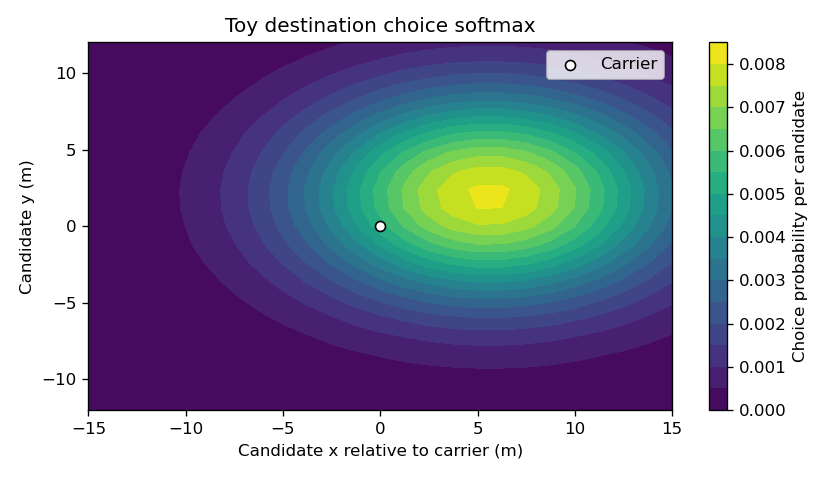

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Deterministic toy candidate scores; this demonstrates the wrapper's softmax normalization.
x,y=np.meshgrid(np.linspace(-15,15,25),np.linspace(-12,12,21)); score=-(x-4)**2/90-(y-2)**2/45+0.035*x
flat=score.ravel(); e=np.exp(flat-flat.max()); p=e/e.sum(); field=p.reshape(score.shape)
fig,ax=plt.subplots(figsize=(7,4)); im=ax.contourf(x,y,field,levels=18,cmap="viridis"); fig.colorbar(im,ax=ax,label="Choice probability per candidate"); ax.scatter([0],[0],c="white",edgecolor="black",label="Carrier"); ax.set(xlabel="Candidate x relative to carrier (m)",ylabel="Candidate y (m)",title="Toy destination choice softmax"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_03_transition.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.

The pitch view below uses the package plotting function and the computed values for frame 5, inside an action interval rather than at its start. It shows probability mass on the original candidate destinations, conditional on passing. Candidate fields use a coarse demonstration grid; the synthetic fixture and grid are not a benchmark.


model: skillcorner_outfield_pass_selection_flat_v3
choice probabilities: [2.92238475e-06 6.15794521e-06 2.93837137e-05 3.09251105e-04
 7.60162969e-04 2.71408984e-03 3.17493515e-04 5.05744314e-04
 2.65598671e-04 4.65507126e-04 8.14435704e-04 2.04136964e-04
 1.40745116e-05 2.71449614e-06 2.99680840e-05 9.40881834e-05
 2.59695587e-03 6.97840268e-04 1.31827400e-01 9.45660408e-04
 1.70169870e-03 1.09404054e-03 8.93985450e-04 4.93088227e-04
 1.18199868e-04 3.32361171e-05 9.89738414e-06 4.12451060e-05
 2.57731279e-04 3.14997461e-04 1.72652466e-03 9.01715548e-02
 4.53063762e-03 3.16126521e-03 3.54680987e-02 1.34063754e-03
 1.05485671e-03 2.40214163e-04 9.88850444e-05 6.94498804e-06
 2.81146686e-04 4.21994407e-04 6.87307004e-04 1.80714510e-03
 2.82650411e-03 1.66403438e-03 6.25440251e-03 5.14537638e-02
 1.54881607e-03 5.55957478e-04 3.28131906e-04 1.06908638e-04
 8.01176140e-06 3.14976117e-04 2.98373954e-04 1.10235502e-03
 1.63296469e-03 5.64832975e-01 4.25337081e-03 2.51585097e-03
 3.80966117e

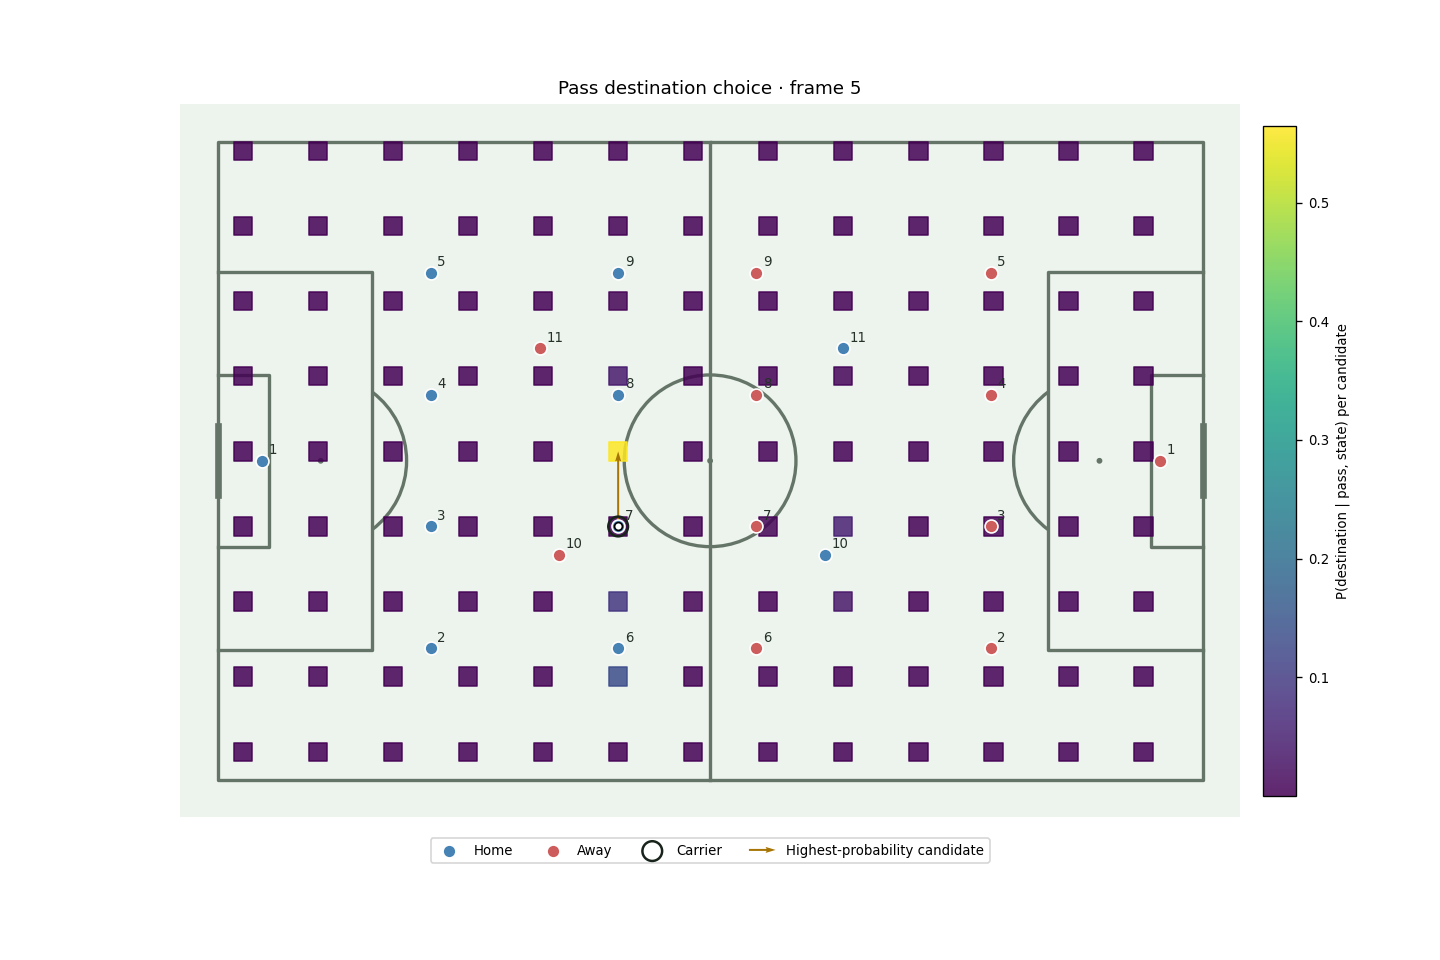

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
model.compute_ball_drive_loss(frame_id)
model.compute_transition_probabilities(frame_id, xT_grid, match_clock_min=0.5, score_difference_prefix=0)
result = model.get_ppcf_result(frame_id)
print("model:", result["transition_model_id"])
print("choice probabilities:", np.asarray(result["Transition probabilities"]))
print("probability sum:", float(np.sum(result["Transition probabilities"])))

from PRESS.visualization import plot_transition
fig, ax = plot_transition(model, frame_id)
out = Path("figures/vignette_03_transition_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))


## Inspect the corrected counts

The following table uses the actual demo state and candidate grid. Each count concerns players beyond a transverse line toward the carrier team’s opposing goal. It is not a count limited to the interval between carrier and target. We show backward, nearby and forward candidate locations. The complete choice probabilities reconstructed from these features must match the frame API output.


In [7]:
import pandas as pd
from PRESS.model import PassSelectionModel

choice = PassSelectionModel.pretrained()
state = model.get_state(frame_id)
features = choice.build_features(
    x_bc=state["x_bc"], v_bc=state["v_bc"],
    r_atts=state["r_atts"], r_defs=state["r_defs"],
    targets=result["grid"], attacking_side=state["attacking_side"],
    target_pitch_control=result["Attacking pitch control field"],
    ball_drive_prob=model.get_ball_drive_result(frame_id)["Ball drive loss probability"],
    pitch_length=state["pitch_length"], pitch_width=state["pitch_width"], **result["transition_context"],
)
count_names = ["opponents_ahead_bc", "teammates_ahead_bc",
               "opponents_ahead_target", "teammates_ahead_target"]
indices = [choice.feature_names.index(name) for name in count_names]
direction = 1 if state["attacking_side"] == "left_to_right" else -1
longitudinal = direction * result["grid"][:, 0]
selected = [np.argmin(longitudinal),
            np.argmin(np.linalg.norm(result["grid"]-state["x_bc"], axis=1)),
            np.argmax(longitudinal)]
print("feature contract:", choice.feature_contract)
print("encoded features:", len(choice.feature_names))
assert choice.feature_contract == "ahead_of_carrier_and_target_v1"
assert np.allclose(choice.predict_features(features), result["Transition probabilities"], atol=1e-12)
counts = pd.DataFrame(features[selected][:, indices].astype(int), columns=count_names,
                      index=["backward target", "near carrier", "forward target"])
counts.insert(0, "forward_displacement_m",
              direction * (result["grid"][selected, 0] - state["x_bc"][0]))
print(counts.to_string())


feature contract: ahead_of_carrier_and_target_v1
encoded features: 50
                 forward_displacement_m  opponents_ahead_bc  teammates_ahead_bc  opponents_ahead_target  teammates_ahead_target
backward target                   -40.0                   9                   2                      11                      10
near carrier                        0.0                   9                   2                       9                       2
forward target                     56.0                   9                   2                       1                       0


## Load a verified full-data export

The installed full-data model is available without fitting:

```python
from PRESS.model import PassSelectionModel
choice = PassSelectionModel.pretrained()
press = PRESS(tracking, pass_selection_model=choice)
press.compute_ppcf(frame_id)  # native full-pitch grid with the final choice model
press.compute_ball_drive_loss(frame_id, t_press=1.0)
probability = press.compute_transition_probabilities(
    frame_id, xT_grid,
    start_type_raw="pass_reception", previous_action_raw="ball_drive",
    match_clock_min=32.5, score_difference_prefix=0,
)
```

Use the actual raw context labels at the frame. The model reads its own fitted xT and vocabulary; the positional `xT_grid` remains for legacy API compatibility. The runnable demo above uses this installed flat ensemble on a deliberately coarse grid. The default full native grid matches the benchmark; changing its cells changes the categorical denominator. `from_json(path)` can load another verified export explicitly. The secondary CNL refit is retained in research history.